# Function 6 - Week 5: observation review

Review what the completed experiments have shown before using a model to choose the next query. This notebook follows the Week 4 measured-output, progress and full-input-profile pattern.

The independent Week 5 `observations.csv` contains **20 initial observations and four returned queries**, including the Week 4 return received on **23 October 2026**. Larger signed outputs are better; all 5 input settings lie in `[0, 1)`. Earlier weekly notebooks retain the evidence and reasoning available at those times.


In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_6/Week_05 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The four later rounds
each contain one deliberately selected query.

In [3]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4', 'x5']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 6.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 20, 1: 1, 2: 1, 3: 1, 4: 1}:
    raise ValueError("This review expects the fixed Week 5 snapshot through round 4.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 5"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,5
1,Initial observations,20
2,Returned queries,4
3,Total observations,24
4,"Queries available, including Week 5",9


Weekly queries used: 4/13


## 2. Place the latest return among the observed outputs

The Week 4 return is **-0.917070253365**, ranked **5/24 (1 = highest output)**. It does not improve the incumbent of **-0.378691254548** (round-01).

In [4]:
print(output_review["report"])

Latest recorded submission: round 4 (1 new output).
Compared with 23 earlier observations (24 outputs in total).
Earlier output range: [-2.57116963161, -0.378691254548].

round-04: y = -0.917070253365 (negative); rank 5/24 (1 = highest output).
Inputs: x1 = 0.28362, x2 = 0.019172, x3 = 0.689432, x4 = 0.559026, x5 = 0
Within the earlier output range.


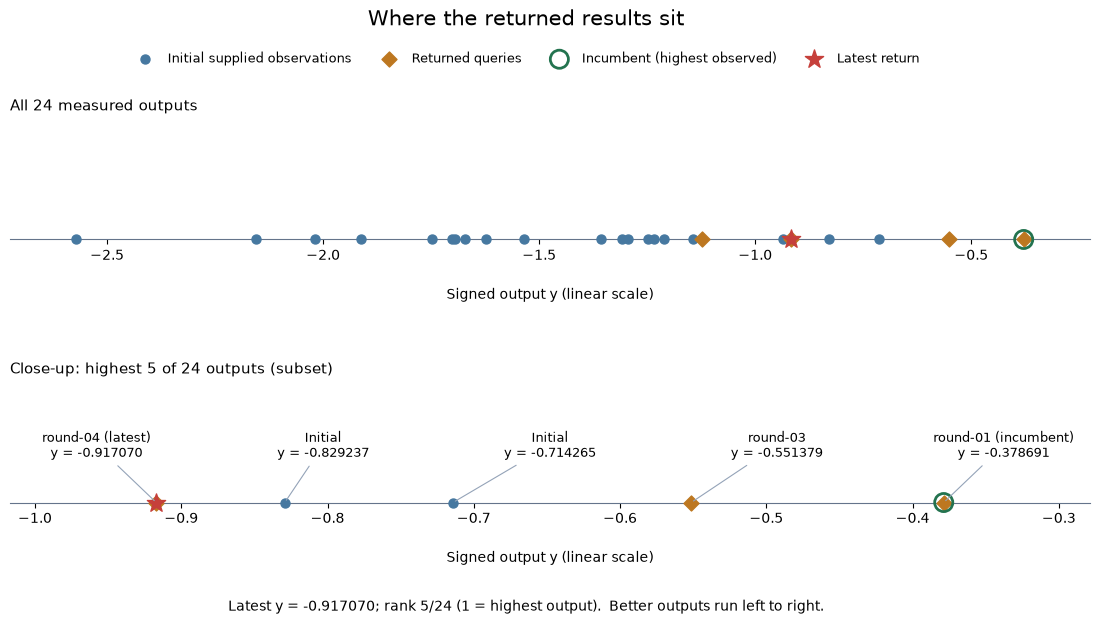

In [5]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 24 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. The later queries were
chosen using earlier evidence, so this view does not estimate the distribution
of scores throughout the input domain or establish the unknown global maximum.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in the
function's original output units.

In [6]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,-0.714265,—
Round 1,-0.378691,-0.378691,0.335574
Round 2,-1.124281,-0.378691,-0.745590
Round 3,-0.551379,-0.378691,-0.172688
Round 4,-0.917070,-0.378691,-0.538379


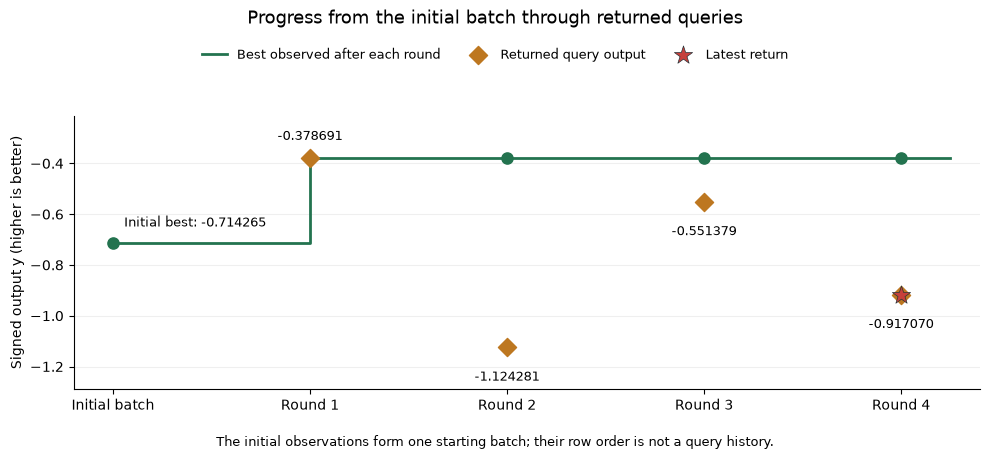

In [7]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

Round 1 remains the only returned query that improved the incumbent. The latest output is lower than round 3 and the initial best, but higher than round 2. Three subsequent non-improvements warrant reviewing the model and acquisition assumptions; they do not establish that the function cannot improve.

The best observed output has changed from **-0.714265** in the initial batch to **-0.378691**, a total gain of **0.335574 output units**. The latest return minus the previous best is **-0.538379**.

## 4. Examine the strongest input combinations

Keep all five coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [8]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,x5,y
observation_id,,,,,,,,
round-01,1,1,0.344331,0.260596,0.575965,0.745346,0.066311,-0.378691
round-03,2,3,0.361714,0.068821,0.707704,0.977540,0.103049,-0.551379
initial-001,3,0,0.728186,0.154693,0.732552,0.693997,0.056401,-0.714265
initial-005,4,0,0.618812,0.331802,0.187288,0.756238,0.328835,-0.829237
round-04,5,4,0.283620,0.019172,0.689432,0.559026,0.000000,-0.917070


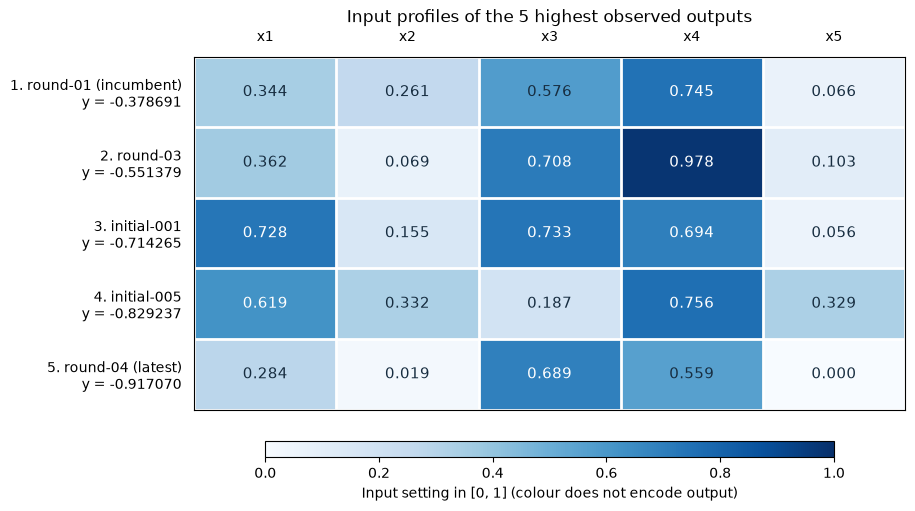

In [9]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

Rounds 1 and 3 remain the two highest observations; round 4 now appears at rank 5. The latest query sets **x5 = 0** and gives a lower output than the incumbent, which has **x5 = 0.066311**. All other settings differ as well. This comparison cannot attribute the lower output to x5 alone or justify excluding the boundary.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [10]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full five-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.344331,0.283620,-0.060711
x2,0.260596,0.019172,-0.241424
x3,0.575965,0.689432,0.113467
x4,0.745346,0.559026,-0.186320
x5,0.066311,0.000000,-0.066311


Previous best: round-01; y = -0.378691
Full five-input distance to previous best: 0.337577
Latest output minus previous best: -0.538379
Nearest earlier observation: round-01 (distance 0.337577)
Repeated full input combinations: 0


The previous best is **round-01**; its full 5-input distance from round 4 is **0.337577**. The nearest earlier observation is **round-01** (distance **0.337577**). The latest output is **0.538379 lower** than the previous best.

All coordinates share the same input range, but Euclidean distance does not account for different input relevance or predict an output change. Several settings changed together. No identical-input repeats are available to measure repeat-evaluation noise.

## 5. Carry the evidence into model review

The incumbent has stayed unchanged since round 1, and the latest low-x5 boundary query returned below the initial best. Review errors at the strongest observations and the balance between predicted mean and uncertainty before choosing another query.

A subsequent Week 5 model study should compare held-out prediction errors with the mean baseline, inspect uncertainty and noise sensitivity, and review candidate selection with **nine query opportunities remaining**, including Week 5.

The [saved Week 4 model notebook](../Week_04/model_predictions.ipynb) is the historical source for the submitted query and forecast. This observation review does not refit it or select a new query. Week 4 evaluation is confirmed in the [submission log](../../../submissions/README.md).

**Historical forecast check:** the [saved Week 4 model run](../Week_04/model_predictions.ipynb) predicted **-0.620624** for the submitted input. The measured return was **-0.917070**, or **0.296446 lower**. The saved forecast is rounded to six decimals. This comparison uses a prediction made before its answer was known; a single forecast error does not establish calibration.